<a href="https://colab.research.google.com/github/siddala2005-ship-it/aimlApnaColg/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns

In [ ]:
insurance_data=pd.read_csv("insurance.csv")

In [ ]:
print(insurance_data)

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


<Axes: xlabel='bmi', ylabel='charges'>

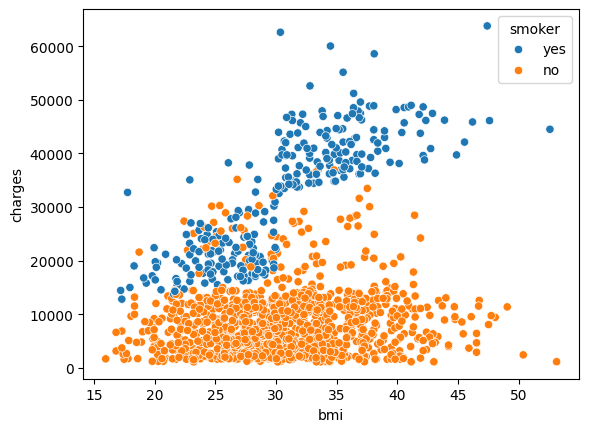

In [ ]:
sns.scatterplot(x=insurance_data["bmi"],y=insurance_data["charges"],hue=insurance_data["smoker"])

<Axes: xlabel='bmi', ylabel='charges'>

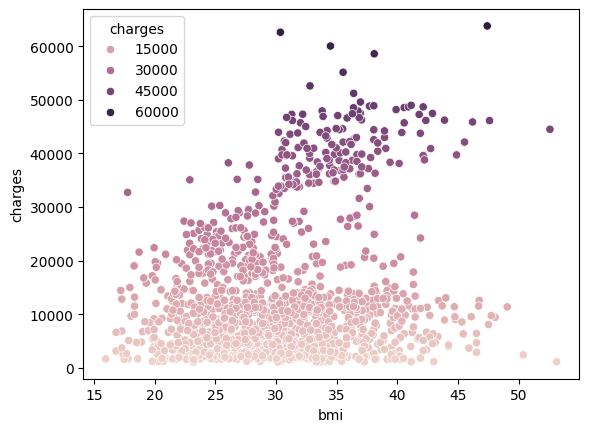

In [ ]:
sns.scatterplot(x=insurance_data["bmi"], y=insurance_data["charges"], hue=insurance_data["charges"])

In [ ]:
##input features
x=insurance_data.drop(columns=["charges","region"])
##output features
y=insurance_data["charges"]

##mapping the smokers and non smokers as 1 and 0;
x["smoker"]=x["smoker"].map({"yes":1,"no":0})
##mapping the sex for male:1, female as 0
x["sex"]=x["sex"].map({"male":1,"female":0})

In [ ]:
##used to see the total data
x.head()


,age,sex,bmi,children,smoker
0,19,0,27.900,0,1
1,18,1,33.770,1,0
2,28,1,33.000,3,0
3,33,1,22.705,0,0
4,32,1,28.880,0,0


In [ ]:
y.head()

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520


train test split

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
x_train.head()

,age,sex,bmi,children,smoker
560,46,0,19.95,2,0
1285,47,0,24.32,0,0
1142,52,0,24.86,0,0
969,39,0,34.32,5,0
486,54,0,21.47,3,0


train

In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

MODEL TEST

In [ ]:
predict=model.predict(x_test)

<Axes: xlabel='charges'>

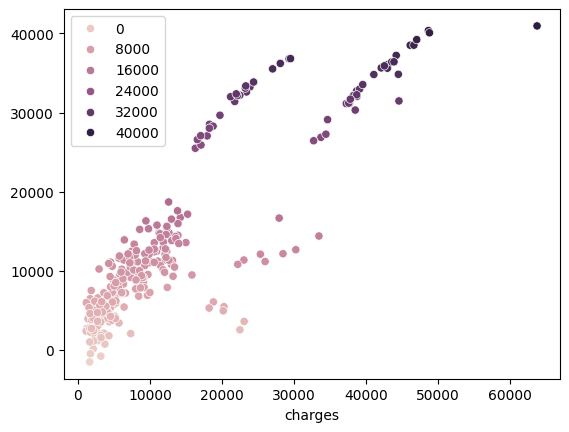

In [ ]:
sns.scatterplot(x=y_test,y=predict,hue=predict)
##y_test=actual values predict=predict test


In [ ]:
y_test.head()

,charges
764,9095.06825
887,5272.17580
890,29330.98315
1293,9301.89355
259,33750.29180


In [ ]:
##evaluation matrix
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
print("r2 score",r2_score(y_test,predict))
print( "mean absolute",mean_absolute_error(y_test,predict))
##adjusted r2
##n=no.of rows p=no.of colums or features
n=x_test.shape[0]
p=x_test.shape[1]
r2=r2_score(y_test,predict)
adjusted_r2=1-((1-r2)*(n-1)/(n-p-1))
print("adjusted",adjusted_r2)

r2 score 0.7811302113434095
mean absolute 4213.484797807137
adjusted 0.7769533069797342
